# Lepton-jet reconstruction efficiency, step 2: the control samples in simulation, and the safety check

Step 2 of [`lj_reco_efficiency.md`](lj_reco_efficiency.md) compares data and simulation in
control samples. This notebook is its simulation part, which comes first: what the two control
samples hold, the efficiencies the simulation expects, and the safety check that decides which of
their regions may be read in data. **It reads no data.** A data step reads only the regions this
notebook marks safe: it calls `systematics_study.require_safe` on the table written to EOS at the
end of section 3.

**The control samples** (channels in `sidm/configs/selections.yaml`, campaign `lj_reco_cr_v2`:
the 96 signal points of the limit grid and every background):

* `lj_cr_Z_to_mumugamma`, for egamma-type lepton jets: exactly two selected PF muons of opposite
  charge with $35 < m(\mu\mu) < 85$ GeV, and as probe any reconstructed photon with $p_T > 20$
  GeV, $|\eta| < 2.4$, $\Delta R > 0.5$ from both muons and $60 < m(\mu\mu\gamma) < 120$ GeV;
* `lj_cr_JPsi_to_mumu`, for muon-type lepton jets: as probe any two tracker muons of opposite
  charge with $|\eta| < 2.4$, $2.6 < m(\mu\mu) < 3.6$ GeV, $\Delta R < 0.4$ and
  $p_T(\mu\mu) > 20$ GeV. No other part of the dimuon mass spectrum is filled.

In both, the lepton jets are built and selected as in step 1, and a probe passes when a selected
lepton jet of the tested type lies within $\Delta R < 0.2$. The probes come from the uncut
collections, so their definition does not depend on the lepton jets. **What data will read** are
the versions `lj_cr_Z_to_mumugamma_alone` and `lj_cr_JPsi_to_mumu_alone`, whose probes have no
other lepton jet of the signal selection's kinds (in `ljs`, two or more muons or none) farther
than $\Delta R = 0.4$ away: an event of the signal region holds two such lepton jets, so none of
its probes enters, and region A is never read. Every number of this notebook is for those
versions; the versions without the condition are used only to check, in simulation, that it
does not change the passing fraction (section 4). The background under each
mass peak is subtracted with the sidebands: for the Z, peak 85 to 95 GeV and sidebands 75 to 85
and 95 to 105 GeV (the photons that do not come from the Z make a background that rises steeply
with $m(\mu\mu\gamma)$, so the sidebands sit next to the peak; section 4); for the J/ψ, peak 2.9
to 3.3 GeV and sidebands 2.6 to 2.9 and 3.3 to 3.6 GeV. The simulation keeps the provisional lepton scale factors (corrections `default`), so the
data/simulation ratios of the data step measure what they miss.

**The safety check** applies the group's criteria, as in the working-point decks: judged in
simulation, worst case over the 96 points at their model cross sections, a region is safe if it
expects under one signal event, or if $S/(S+B) < 5\%$ and $Z < 1$, and not safe if
$S/(S+B) > 10\%$ or $Z > 2$. Section 3 gives the details, including one rule stricter than the
decks.

In [1]:
import os, shutil, sys, tempfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

INPUT_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DIR)            # the merged outputs of lj_reco_cr_v2
OUTPUT_DIR = sysstudy.eos_url(sysstudy.LJ_CR_RESULTS_DIR)   # the safety table and the figures
if not sysstudy.list_coffea(INPUT_DIR):
    raise FileNotFoundError(
        f"No merged outputs in {INPUT_DIR} yet. Run the lj_reco_cr_v2 campaign first, from the "
        "repository root: python condor/campaign.py lj_reco_cr_v2 jobs, then submit, then status "
        "with retry --submit and skipped --submit until every chunk is done, then merge "
        "(condor/README.md, section 23).")
WORK = Path(tempfile.mkdtemp(prefix="lj_reco_cr_v2_"))   # removed at the end


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


print("inputs: ", INPUT_DIR)
print("outputs:", OUTPUT_DIR)

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v2
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v2_results


## 1. Inputs

One pass over the merged simulation outputs, keeping the probe histograms
(`systematics_study.lj_cr_inputs`, which stops at any data sample). The signal is at the 1 fb
reference here and is scaled to the model cross sections where it is used. Below, per control
sample: the simulated background in the mass peak by group, what the sidebands subtract, and the
effective number of simulated events.

In [2]:
inputs = sysstudy.lj_cr_inputs(INPUT_DIR)
print(len(inputs["signal"]), "signal points,", len(inputs["background"]), "background samples\n")
for cr, spec in sysstudy.LJ_CR.items():
    (lo, hi), sidebands = spec["peak"], spec["sidebands"]
    k = (hi - lo) / sum(b - a for a, b in sidebands)
    print(f"{cr}: probes in the peak ({lo:g} to {hi:g}) by group")
    total_peak = total_side = 0.0
    for group, samples in sysstudy.LJ_CR_GROUPS.items():
        hists = [inputs["background"][s][cr] for s in samples if s in inputs["background"]]
        if not hists:
            continue
        h = sum(hists)
        peak = sysstudy.mass_window(h, spec["mass"], lo, hi).sum(flow=True)
        side = sum(sysstudy.mass_window(h, spec["mass"], a, b).sum(flow=True).value for a, b in sidebands)
        neff = peak.value ** 2 / peak.variance if peak.variance > 0 else 0.0
        print(f"   {group:18s} {peak.value:12.4g}  (effective events {neff:9.1f}); sidebands x {k:.2f}: {k * side:12.4g}")
        total_peak, total_side = total_peak + peak.value, total_side + k * side
    print(f"   {'total':18s} {total_peak:12.4g}; after the sideband subtraction {total_peak - total_side:12.4g}\n")

96 signal points, 18 background samples

Z -> mumu gamma: probes in the peak (85 to 95) by group
   DY$\to\ell\ell$       1.432e+04  (effective events    4277.1); sidebands x 0.50:         3935
   QCD                        2489  (effective events      13.7); sidebands x 0.50:         2706
   $t\bar{t}$                 1541  (effective events     474.1); sidebands x 0.50:         1762
   diboson                   50.98  (effective events     213.8); sidebands x 0.50:        29.98
   total                  1.84e+04; after the sideband subtraction         9966

J/psi -> mumu: probes in the peak (2.9 to 3.3) by group
   DY$\to\ell\ell$            7393  (effective events    2208.8); sidebands x 0.67:         7414
   QCD                     4.7e+05  (effective events    2461.5); sidebands x 0.67:    9.021e+04
   $t\bar{t}$                 2897  (effective events     889.9); sidebands x 0.67:        845.2
   diboson                   30.39  (effective events     124.2); sidebands x 0.67:    

**Interpretation (run of 2026-11-16: `lj_reco_cr_v2`, 96 signal points, 18 background samples).**

*$Z \to \mu\mu\gamma$.* 18,400 simulated probes fall in the peak window, 78% of them from
Drell-Yan, 14% from QCD and 8% from $t\bar t$; after the sideband subtraction about 10,000
remain. The QCD part rests on 14 effective simulated events, so its contribution, and any
estimate that includes it, carries large statistical fluctuations.

*$J/\psi \to \mu\mu$.* 480,000 probes in the peak window, 98% from QCD, that is $J/\psi$ from
b-hadron decays (the simulation has no prompt $J/\psi$), with 2,460 effective events. The
Drell-Yan probes are pairs of a Z muon with a nearby soft muon and are flat in mass: the
sidebands remove them completely (7,393 in the peak against 7,414 from the sidebands). About
380,000 probes remain after the subtraction.

## 2. The probes in simulation

Per control sample, the probe mass and the probe $p_T$: the simulated background stacked by
group, and the three signal points that put the most probes into the control sample, at their
model cross sections. These are the distributions whose tails the safety check looks at.

Z -> mumu gamma: most signal at the model cross section: 4Mu_800GeV_1p2GeV_1p2mm 0.0102, 4Mu_800GeV_1p2GeV_6p0mm 0.00831, 4Mu_800GeV_5p0GeV_25p0mm 0.0026


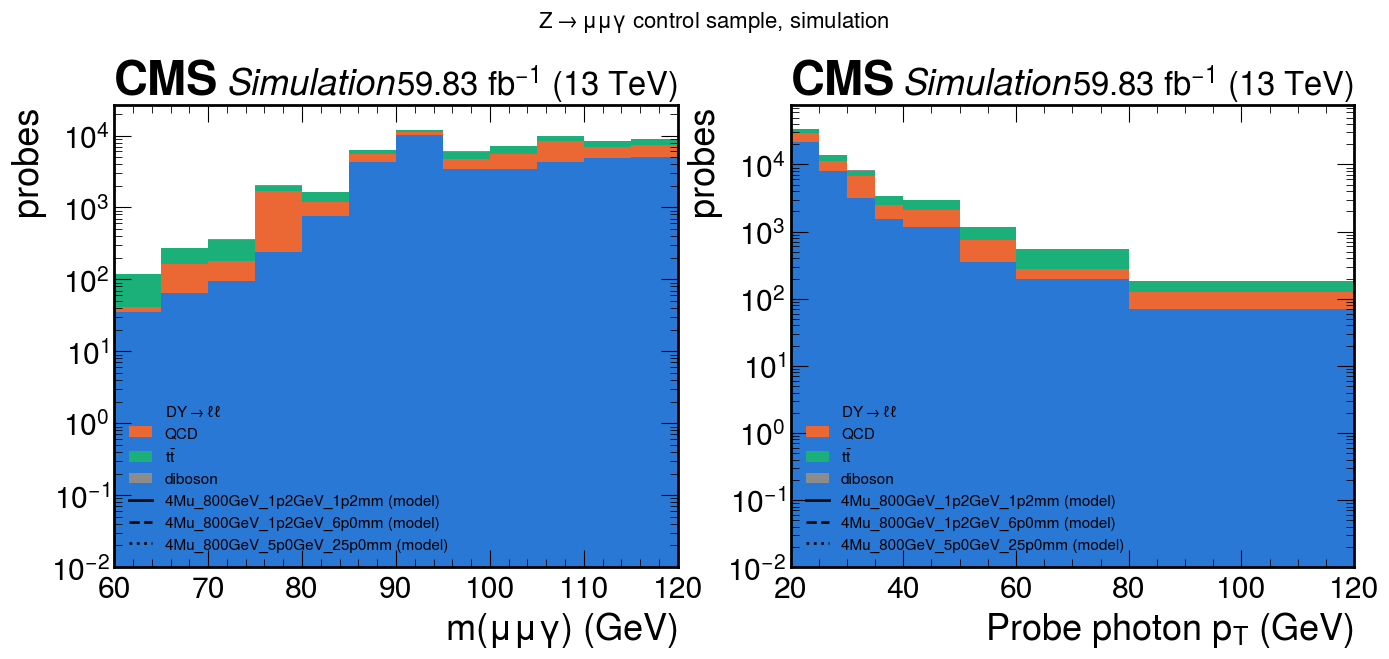

J/psi -> mumu: most signal at the model cross section: 4Mu_800GeV_5p0GeV_5p0mm 5.17, 4Mu_800GeV_5p0GeV_25p0mm 3.43, 4Mu_800GeV_1p2GeV_1p2mm 2.7


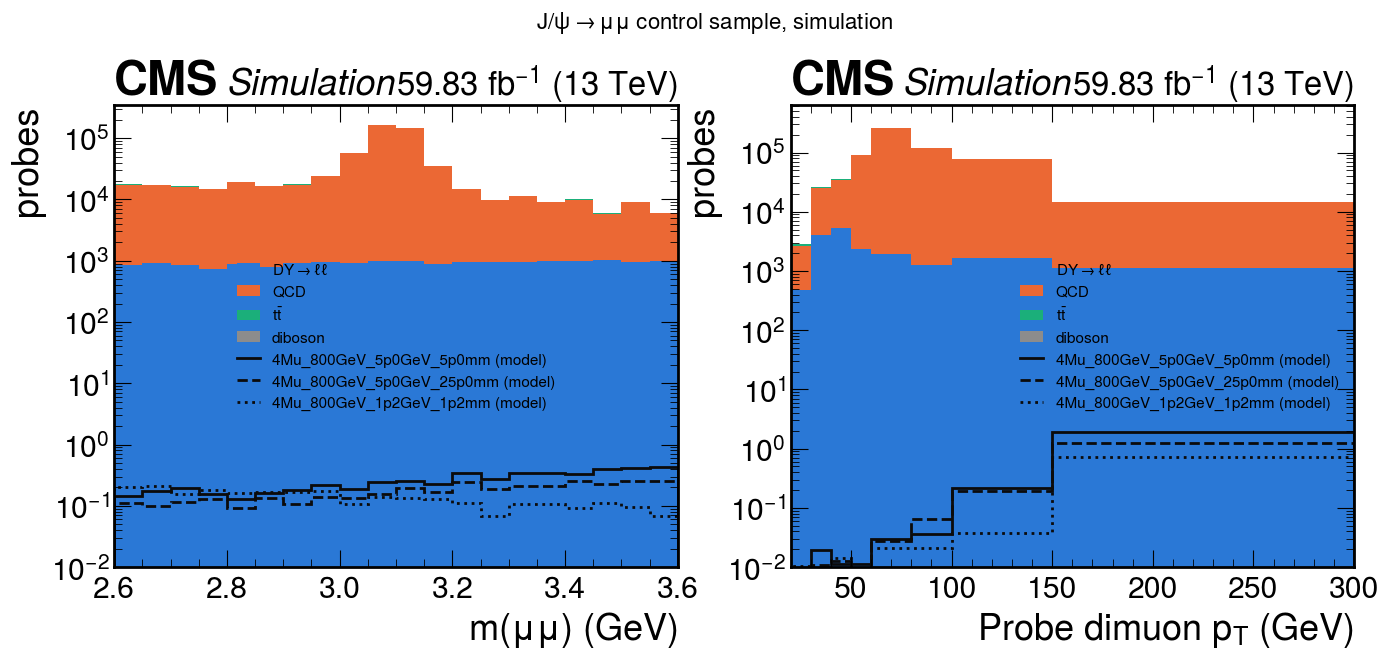

In [3]:
# pylint: disable-next=import-error
import plot_tools as pt
XS = pt.theory_xs_fb()
for cr, spec in sysstudy.LJ_CR.items():
    yields = {p: per[cr].sum(flow=True).value * XS[p] for p, per in inputs["signal"].items() if p in XS}
    top = sorted(yields, key=yields.get, reverse=True)[:3]
    print(f"{cr}: most signal at the model cross section: " +
          ", ".join(f"{p} {yields[p]:.3g}" for p in top))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sysstudy.plot_probe_distribution(inputs, cr, spec["mass"], points=top, ax=axes[0])
    sysstudy.plot_probe_distribution(inputs, cr, "probe_pt", points=top, ax=axes[1])
    fig.suptitle(f"{spec['label']} control sample, simulation", fontsize=16, y=1.04)
    study.cms_label(axes, lumi=59.83)
    save(fig, f"probes_{spec['channel']}")
    plt.show()

The Z peak needs a closer look: above 30 GeV, where a probe can pass, the probe mass of the
passing and failing probes by process (the windows of the subtraction marked).

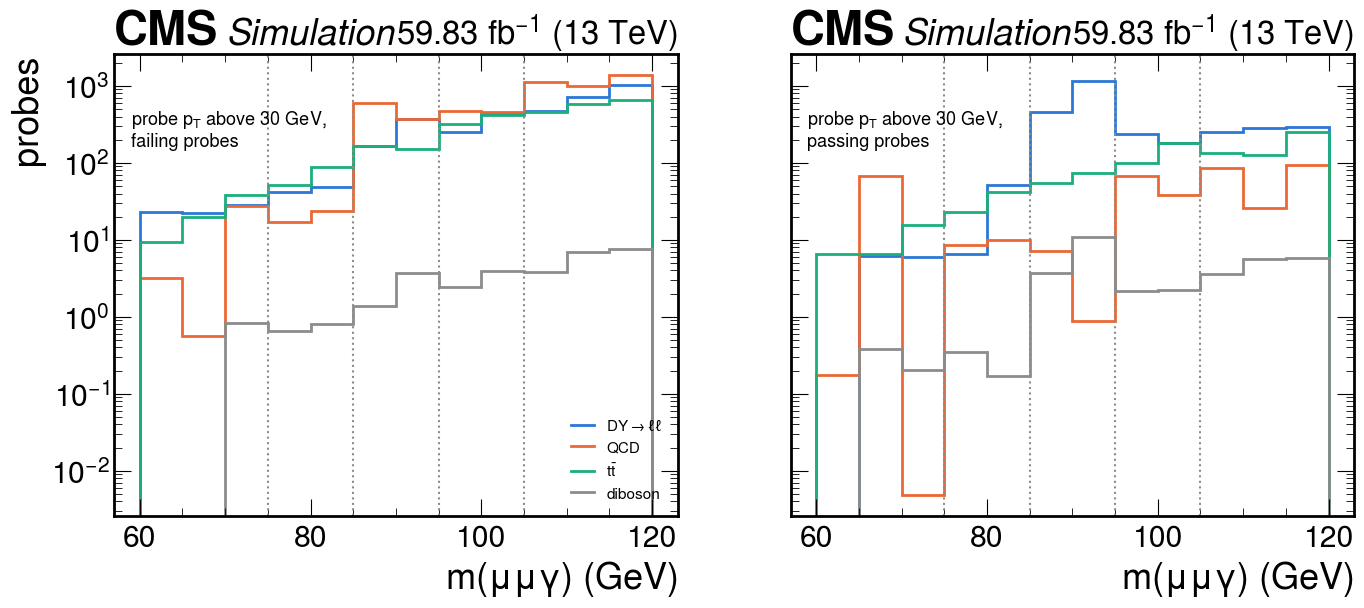

In [4]:
import hist
spec = sysstudy.LJ_CR["Z -> mumu gamma"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (passing, title) in zip(axes, ((0, "failing probes"), (1, "passing probes"))):
    for (group, samples), colour in zip(sysstudy.LJ_CR_GROUPS.items(), (study.BLUE, study.ORANGE, study.AQUA, study.GRAY)):
        hists = [inputs["background"][s]["Z -> mumu gamma"] for s in samples if s in inputs["background"]]
        m = sum(hists)[{"probe_pt": slice(hist.loc(30), None, sum), "passing": passing}].project("m_mmg")
        ax.stairs(m.values(), m.axes[0].edges, color=colour, linewidth=2, label=group)
    for edge in (spec["sidebands"][0][0], spec["peak"][0], spec["peak"][1], spec["sidebands"][1][1]):
        ax.axvline(edge, color=study.GRAY, linestyle=":")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m(\mu\mu\gamma)$ (GeV)")
    ax.text(0.03, 0.80, f"probe $p_T$ above 30 GeV,\n{title}", transform=ax.transAxes, fontsize=13)
axes[0].set_ylabel("probes")
axes[0].legend(fontsize=11, loc="lower right")
study.cms_label(axes, lumi=59.83)
save(fig, "zmmg_mass_pass_fail")
plt.show()

**Interpretation.** The $J/\psi$ peak stands on a flat background, which the linear sideband
subtraction suits. The worst signal points (4Mu at 800 GeV with 5 GeV and 1.2 GeV dark photons)
put 0.1 to 0.4 events per 50 MeV bin into the window, flat in mass and nearly all at pair $p_T$
above 150 GeV: mismeasured pairs of displaced dark photons, as the first local test showed.

In the $Z \to \mu\mu\gamma$ sample, the passing probes above 30 GeV show a narrow Z peak, while
the failing probes rise steeply towards 120 GeV in every process: photons that do not come from
the Z (pileup, initial-state radiation, $\pi^0$ in jets) added to a dimuon of lower mass. A
straight line between sidebands 20 GeV away overestimates this background under the peak and
drove the first estimate of the efficiency above one; the peak of 85 to 95 GeV with the adjacent
sidebands of 75 to 85 and 95 to 105 GeV keeps the subtraction close to linear (the Drell-Yan
efficiency it gives agrees with a quadratic fit of the sidebands, 0.87 above 30 GeV).

## 3. The safety check

`systematics_study.lj_cr_safety` judges, for each control sample, the whole probe histogram,
each bin of the probe $p_T$ (with every other axis kept), and the union of the $p_T$ bins that
pass only through the $S < 1$ rule (which per region does not bound their sum). Every quantity is
taken at its worst over the 96 points at their model cross sections. For each region:

* **counting**: the integrated $S/(S+B)$ and the Asimov $Z$;
* **shape**: the same with the binned $Z$ over every bin with background;
* **sparse bins**: the bins expecting under one background event, judged together as one more
  region. This rule is stricter than the decks, which report that signal but leave it out of the
  verdict: a fine histogram can hold a signal-dominated tail there while the region passes as a
  whole. It is used with the user's agreement (2026-11-16) until the advisor rules on it
  (`STRICT_SPARSE_BINS` in `systematics_study.py` switches it off);
* each verdict again with the heaviest simulated background event of the region taken out of its
  bin (the stress test).

A $p_T$ bin may be read in data only if all its verdicts are safe; the table goes to EOS, where
the data step reads it back (`systematics_study.lj_cr_verdicts`, `require_safe`).

In [5]:
rows = sysstudy.lj_cr_safety(inputs)
COLUMNS = ["control sample", "region", "B", "neff", "worst point", "S", "contam", "z", "z_binned_all",
           "s_sparse", "b_sparse", "counting", "shape", "sparse bins", "counting, stress test",
           "shape, stress test", "sparse bins, stress test"]
table = pd.DataFrame(rows)[COLUMNS].rename(columns={"contam": "S/(S+B) [%]", "z_binned_all": "binned Z"})
table["S/(S+B) [%]"] *= 100
with pd.option_context("display.width", 300, "display.max_columns", 30, "display.max_colwidth", 40,
                       "display.float_format", "{:.3g}".format):
    print(table.to_string(index=False))
print()
for cr in sysstudy.LJ_CR:
    print(f"{cr}: may be read in data: {sysstudy.lj_cr_readable(rows, cr)}")
sysstudy.write_verdicts(rows, OUTPUT_DIR)
table.to_csv(WORK / "safety.csv", index=False)
print("\nsafety table written to", OUTPUT_DIR)

 control sample              region        B     neff                  worst point       S  S/(S+B) [%]        z  binned Z  s_sparse  b_sparse counting shape sparse bins counting, stress test shape, stress test sparse bins, stress test
Z -> mumu gamma     whole histogram 6.36e+04      874      4Mu_800GeV_1p2GeV_1p2mm  0.0102     1.61e-05 4.05e-05   0.00483   0.00232      99.7     safe  safe        safe                  safe               safe                     safe
Z -> mumu gamma       probe_pt < 20        0        0 2Mu2E_1000GeV_0p25GeV_0p02mm       0            0        0         0         0         0     safe  safe        safe                  safe               safe                     safe
Z -> mumu gamma   probe_pt 20 to 25 3.34e+04      385      4Mu_800GeV_1p2GeV_6p0mm 0.00432     1.29e-05 2.36e-05  0.000451   0.00232      8.81     safe  safe        safe                  safe               safe                     safe
Z -> mumu gamma   probe_pt 25 to 30 1.37e+04      362   

**Interpretation.** Every region of both control samples is safe, for counting and shape uses,
with the sparse-bin rule and in the stress test, so both may be read in data in full and no cap
on the probe $p_T$ is needed.

* $Z \to \mu\mu\gamma$: the worst signal point (4Mu, 800 GeV, 1.2 GeV, 1.2 mm) puts 0.010 events
  into the whole histogram, against 64,000 background probes: safe through $S < 1$ everywhere,
  whatever the background.
* $J/\psi \to \mu\mu$: below 150 GeV every bin expects at most 0.22 signal events. The two highest
  bins hold the signal of the worst point (4Mu, 800 GeV, 5 GeV, 5 mm): 1.9 events against 14,700
  background probes from 150 to 300 GeV, and 3.0 events against 899 above 300 GeV
  ($S/(S+B)$ = 0.33%, $Z$ = 0.10, binned $Z$ = 0.57; the sparse bins hold 1.4 signal events against
  59 background events). That bin would reach caution only if its background were below about 56
  events, 16 times fewer than the simulation predicts.

The table is on EOS (`lj_reco_cr_v2_results/safety.json`); the data step reads only through it.

## 4. The efficiencies the simulation expects

The passing fraction of the simulated background probes after the sideband subtraction
(`systematics_study.probe_efficiency`), against each probe variable. These are the simulation
side of the data/simulation ratios; their statistical uncertainties follow from the sums of
squared weights.

Z -> mumu gamma, simulated background, probe_pt: 20-25: -0.003 +- 0.007, 25-30: 0.003 +- 0.003, 30-35: 0.567 +- 0.309, 35-40: 0.859 +- 0.362, 40-50: 0.958 +- 0.283, 50-60: 0.954 +- 0.181, 60-80: 1.144 +- 0.294, 80-120: 2.467 +- 1.564
Z -> mumu gamma, Drell-Yan only, probe_pt: 20-25: 0.001 +- 0.002, 25-30: -0.000 +- 0.002, 30-35: 0.861 +- 0.042, 35-40: 0.991 +- 0.083, 40-50: 0.951 +- 0.084, 50-60: 0.791 +- 0.104, 60-80: 0.998 +- 0.158, 80-120: 1.199 +- 0.158
Z -> mumu gamma, simulated background, probe_abseta (pT > 30 GeV): 0-0.8: 0.582 +- 0.316, 0.8-1.4442: 0.745 +- 0.242, 1.4442-1.566: 0.650 +- 0.205, 1.566-2: 1.087 +- 0.151, 2-2.4: nan +- nan
Z -> mumu gamma, Drell-Yan only, probe_abseta (pT > 30 GeV): 0-0.8: 0.903 +- 0.045, 0.8-1.4442: 0.906 +- 0.051, 1.4442-1.566: 0.779 +- 0.138, 1.566-2: 0.990 +- 0.105, 2-2.4: 0.827 +- 0.303
Z -> mumu gamma, simulated background, probe_r9 (pT > 30 GeV): 0-0.5: 1.058 +- 0.962, 0.5-0.8: 0.381 +- 0.492, 0.8-0.9: 0.806 +- 0.774, 0.9-0.94: 1.148 +- 0.3

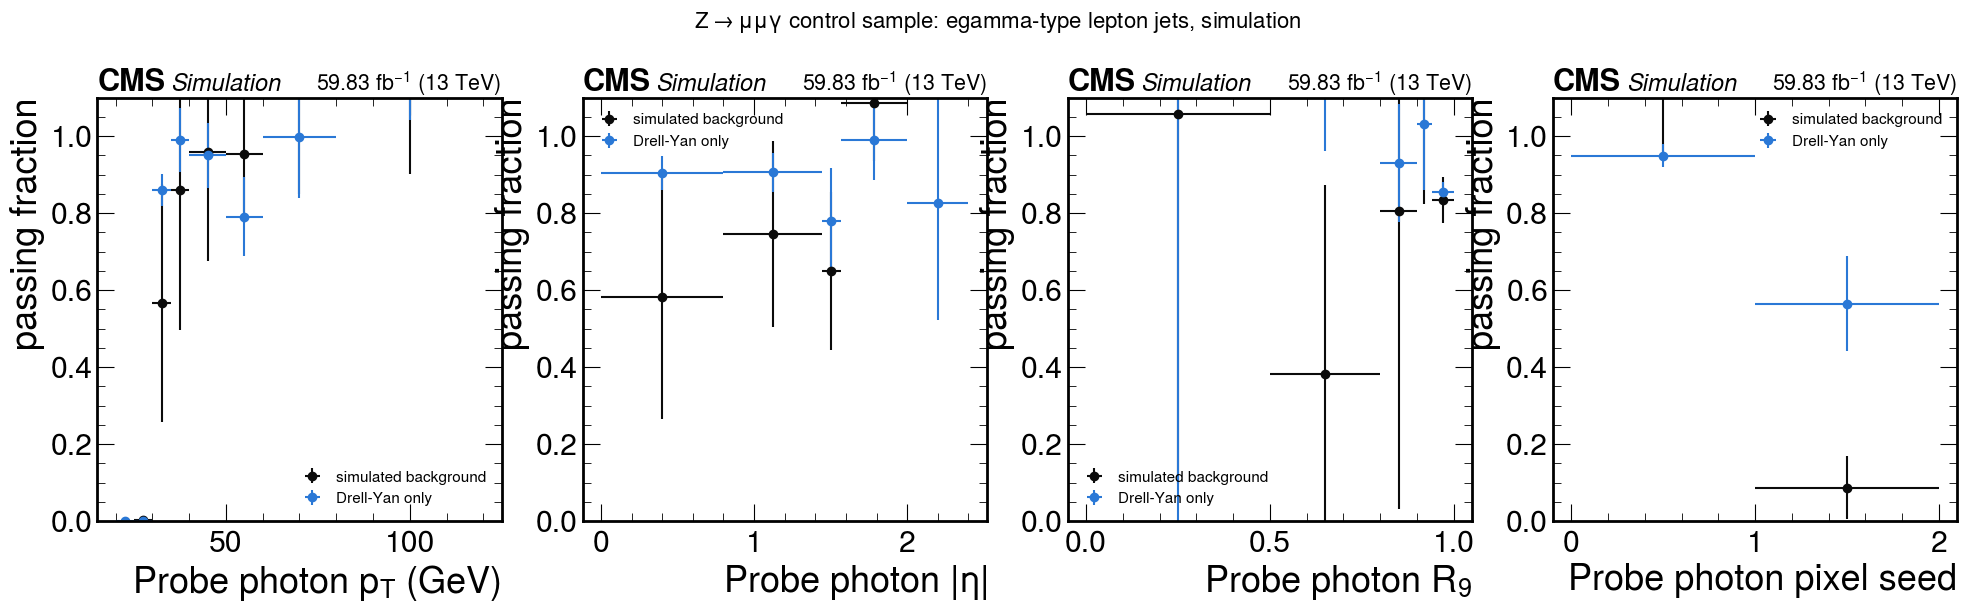

J/psi -> mumu, simulated background, probe_pt: 20-30: 1.318 +- 1.579, 30-40: 0.746 +- 0.106, 40-50: 0.936 +- 0.043, 50-60: 0.962 +- 0.015, 60-80: 1.003 +- 0.012, 80-100: 0.996 +- 0.004, 100-150: 0.990 +- 0.004, 150-300: 1.015 +- 0.059
J/psi -> mumu, simulated background, probe_dR: 0-0.01: nan +- nan, 0.01-0.02: 0.321 +- 0.245, 0.02-0.03: 0.871 +- 0.057, 0.03-0.05: 1.008 +- 0.032, 0.05-0.08: 0.996 +- 0.002, 0.08-0.12: 0.991 +- 0.003, 0.12-0.2: 0.946 +- 0.027, 0.2-0.4: 0.741 +- 0.278
J/psi -> mumu, simulated background, probe_abseta: 0-0.9: 0.993 +- 0.010, 0.9-1.2: 0.976 +- 0.009, 1.2-2.4: 0.973 +- 0.011


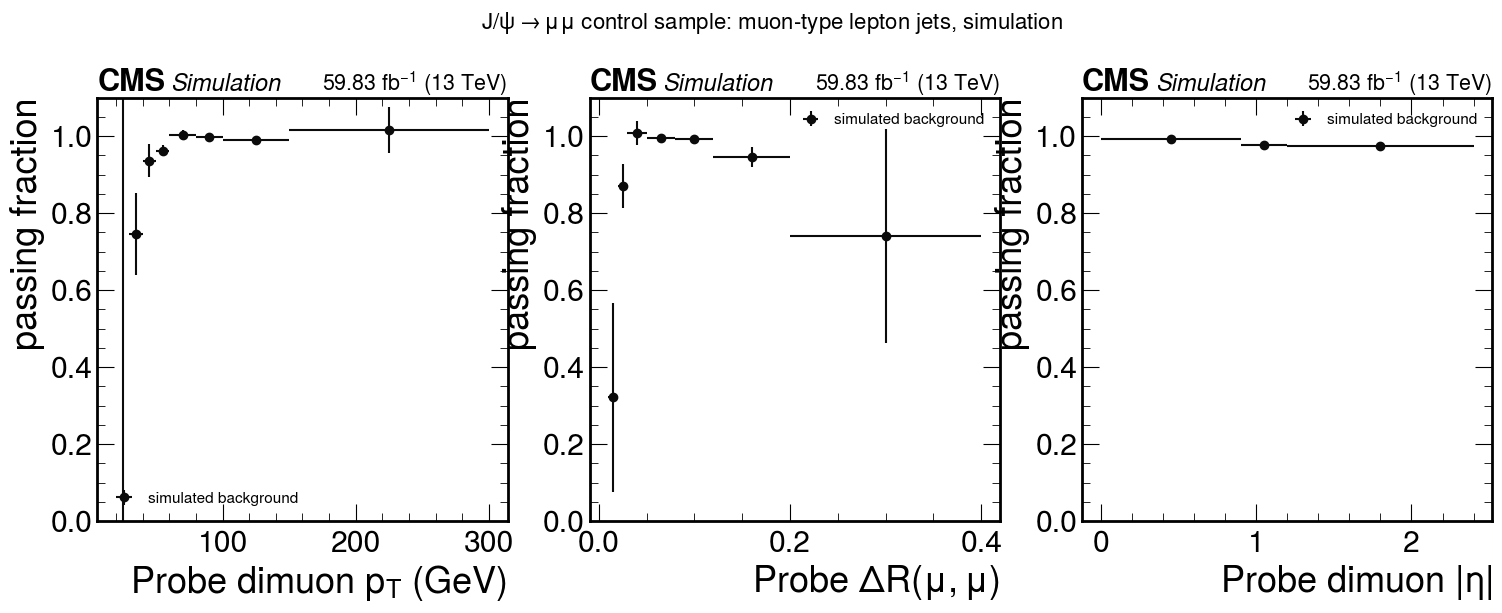

In [6]:
import hist
AXES = {"Z -> mumu gamma": ["probe_pt", "probe_abseta", "probe_r9", "probe_pixelSeed"],
        "J/psi -> mumu": ["probe_pt", "probe_dR", "probe_abseta"]}
for cr, axes_names in AXES.items():
    spec = sysstudy.LJ_CR[cr]
    sources = {"simulated background": sum(per[cr] for per in inputs["background"].values())}
    if cr == "Z -> mumu gamma":
        sources["Drell-Yan only"] = sum(inputs["background"][s][cr] for s in sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
                                        if s in inputs["background"])
    fig, axes = plt.subplots(1, len(axes_names), figsize=(6 * len(axes_names), 5.5))
    for ax, axis in zip(axes, axes_names):
        results = {}
        for label, h in sources.items():
            # an egamma-type lepton jet needs pT > 30 GeV, so the other Z axes are shown above it
            if cr == "Z -> mumu gamma" and axis != "probe_pt":
                h = h[{"probe_pt": slice(hist.loc(30), None, sum)}]
            results[label] = r = sysstudy.probe_efficiency(h, spec, axis)
            print(f"{cr}, {label}, {axis}" + (" (pT > 30 GeV)" if cr.startswith("Z") and axis != "probe_pt" else "")
                  + ": " + ", ".join(f"{lo:g}-{hi:g}: {e:.3f} +- {u:.3f}" for lo, hi, e, u in zip(
                      r["edges"][:-1], r["edges"][1:], sysstudy.in_range(r["axis"], r["eff"]),
                      sysstudy.in_range(r["axis"], r["err"]))))
        sysstudy.plot_probe_efficiency(results, ax=ax)
    fig.suptitle(f"{spec['label']} control sample: {spec['lj_type']} lepton jets, simulation", fontsize=16, y=1.04)
    study.cms_label(axes, lumi=59.83)
    save(fig, f"efficiency_{spec['channel']}")
    plt.show()

The condition on other lepton jets is the same for passing and failing probes, so it should not
change the passing fraction. Below, the passing fraction against the probe $p_T$ in the simulated
background with the condition (the versions data will read) and without it.

Z -> mumu gamma, with the condition (data): probes after the subtraction 9966
Z -> mumu gamma, without it: probes after the subtraction 9715


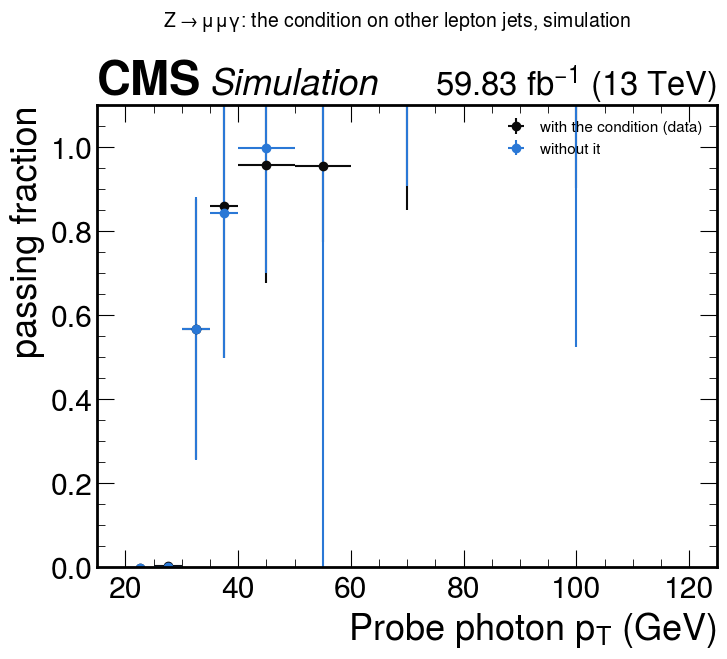

J/psi -> mumu, with the condition (data): probes after the subtraction 3.818e+05
J/psi -> mumu, without it: probes after the subtraction 3.892e+05


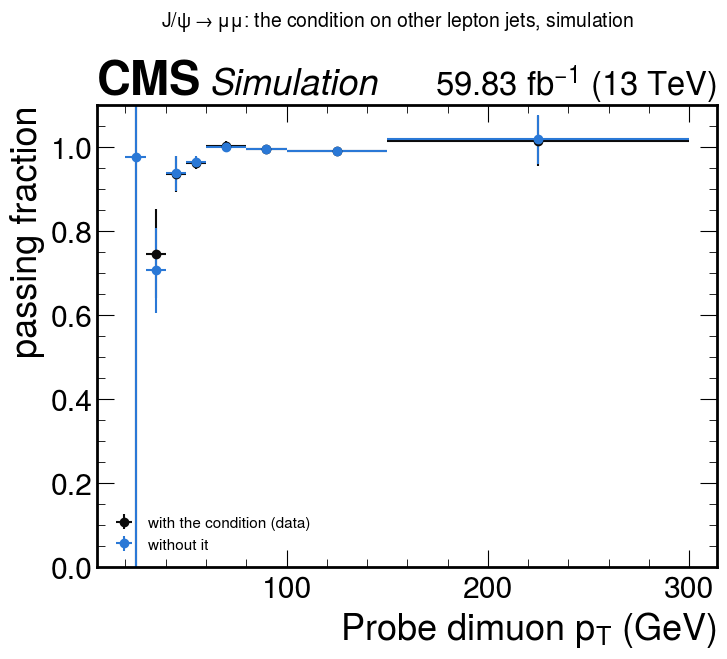

In [7]:
inputs_all = sysstudy.lj_cr_inputs(INPUT_DIR, alone=False)
for cr, spec in sysstudy.LJ_CR.items():
    results = {}
    for label, source in (("with the condition (data)", inputs), ("without it", inputs_all)):
        total = sum(per[cr] for per in source["background"].values())
        results[label] = sysstudy.probe_efficiency(total, spec, "probe_pt")
        print(f"{cr}, {label}: probes after the subtraction "
              f"{np.nansum(results[label]['probes']):.4g}")
    fig, ax = plt.subplots(figsize=(8, 6))
    sysstudy.plot_probe_efficiency(results, ax=ax)
    fig.suptitle(f"{spec['label']}: the condition on other lepton jets, simulation", fontsize=14, y=1.04)
    study.cms_label(ax, lumi=59.83)
    save(fig, f"efficiency_alone_check_{spec['channel']}")
    plt.show()

**Interpretation.**

*Muon-type lepton jets ($J/\psi$).* The passing fraction turns on with the 30 GeV threshold of
the lepton jets (0.75 ± 0.11 from 30 to 40 GeV) and is 0.94 to 1.00 above 40 GeV. Against the
opening angle it is flat near one from $\Delta R$ = 0.03 to 0.12 and falls for the most
collimated pairs: 0.87 ± 0.06 from 0.02 to 0.03, and 0.32 ± 0.25 from 0.01 to 0.02, where the
simulation holds few probes. It is 0.97 to 0.99 in every $|\eta|$ range. The $J/\psi$ pairs cover
$\Delta R$ from 0.02 to 0.4 at $p_T$ from 30 to 300 GeV: the 5 GeV dark photons of the grid, the
1.2 GeV ones in part, not the 0.25 GeV ones (question 4 of `lj_reco_efficiency.md`).

*Egamma-type lepton jets ($Z \to \mu\mu\gamma$).* Below 30 GeV no probe passes, as the
lepton-jet threshold requires. Above it, the photons of Drell-Yan pass in 0.86 ± 0.04 of the
cases from 30 to 35 GeV and 0.95 to 0.99 from 35 to 50 GeV; 0.95 ± 0.03 without a pixel seed and
0.57 ± 0.12 with one (the pixel-seed veto of the lepton-jet photons). With all backgrounds the
estimate agrees with Drell-Yan alone only for unconverted photons ($R_9 \geq 0.94$: 0.83 ± 0.06
against 0.86 ± 0.03); for $R_9 < 0.94$ the probes are dominated by photons that do not come
from the Z, and the subtraction is not reliable there.

*The condition on other lepton jets.* It keeps 98% of the $J/\psi$ probes, and the passing
fractions with and without it agree within their uncertainties in every bin (for example
0.75 ± 0.11 and 0.71 ± 0.10 from 30 to 40 GeV). For the Z, the total after the subtraction even
grows with the condition (9,966 against 9,715), a measure of the fluctuations the QCD weights
bring; the Drell-Yan efficiencies are the same with and without it.

## 5. What this means for the data step

Written for the run of 2026-11-16 (`lj_reco_cr_v2`).

1. **Both control samples may be read in data, in full.** Every region is safe under the group's
   criteria with the stricter sparse-bin rule. The data campaign `lj_reco_cr_data_v1` fills the
   alone versions only, with no cap on the probe $p_T$.
2. **Muon-type lepton jets.** The $J/\psi$ measurement is clean: a peak on a flat background, a
   passing fraction near one above 40 GeV in the simulation, and enough probes for bins in $p_T$,
   $\Delta R$ and $|\eta|$. The data hold prompt and non-prompt $J/\psi$, the simulation only
   non-prompt ones; the lepton-jet selection has no isolation requirement, so the passing
   fraction of a muon pair is not expected to depend on its origin.
3. **Egamma-type lepton jets.** The data/simulation comparison is reliable for unconverted photons
   ($R_9 \geq 0.94$) above 30 GeV, where the subtraction gives the same efficiency whatever the
   background. The converted photons, the closest analogue of the displaced egamma-type lepton
   jets, sit among photons that do not come from the Z; measuring them needs a purer probe (for
   example $m_{\mu\mu} + m_{\mu\mu\gamma} < 180$ GeV and the photon closer to a muon), that is a
   new version of the control sample and new campaigns.
4. **Not covered** by these samples: the displaced DSA muons and the prompt electron pairs
   (question 5 of `lj_reco_efficiency.md`), and the most collimated muon pairs (question 4).

Everything goes to EOS, and the local working directory is removed.

In [8]:
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v2_results
